# Tahap 4: Pemodelan Machine Learning & Evaluasi
**Mata Kuliah:** Data Science 2026  
**Topik:** KingCounty-AVM (Supervised Valuation, Tier Classification & Unsupervised Spatial Clustering)  
**Tujuan Pembelajaran (Sesuai RPS):**
1. **Supervised Learning (Regresi Hedonik):** Menguji dan membandingkan 7 model regresi (OLS, Ridge, Lasso, Elastic Net, Decision Tree, Random Forest, HistGradientBoosting) untuk estimasi nilai pasar properti kontinu ($R^2$, $\text{RMSE}$, $\text{MAPE}$, $\text{MAE}$).
2. **Supervised Learning (Klasifikasi Segmentasi Pasar):** Melatih dan memvalidasi model klasifikasi (Decision Tree, Random Forest, HistGradientBoosting) untuk mengelompokkan kelas properti ke dalam tier pasar (*Entry-Level*, *Mid-Market*, *Luxury*).
3. **Unsupervised Learning (K-Means Clustering):** Menyuntikkan algoritma K-Means ($k=6$) berbasis koordinat geospasial (`Latitude`, `Longitude`) dan nilai logaritmik harga $\ln(\text{SalePrice})$ guna mempartisi wilayah King County ke dalam 6 mikro-pasar properti serta memberdayakan fitur pembanding properti (*empirical comps*).
4. **Interpretasi & XAI:** Menganalisis bobot kontribusi variabel menggunakan Permutation Feature Importance.
5. **Serialisasi Model:** Mengekspor seluruh artefak model biner (`.joblib`) dan metadata JSON untuk integrasi aplikasi web Streamlit.

## 1. Import Pustaka Pemodelan (Supervised & Unsupervised)

In [1]:
import os
import json
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import (
    HistGradientBoostingRegressor, HistGradientBoostingClassifier,
    RandomForestRegressor, RandomForestClassifier
)
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    r2_score, mean_squared_error, mean_absolute_error, 
    mean_absolute_percentage_error, accuracy_score, f1_score, confusion_matrix,
    silhouette_score, calinski_harabasz_score, davies_bouldin_score
)
from sklearn.inspection import permutation_importance

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Pustaka pemodelan (Supervised & Unsupervised Learning) berhasil dimuat.")

Pustaka pemodelan (Supervised & Unsupervised Learning) berhasil dimuat.


## 2. Memuat Dataset Bersih dari `../data/processed/`

In [2]:
clean_path = "../data/processed/king_county_clean.csv"
df = pd.read_csv(clean_path, low_memory=False)
print(f"Data bersih berhasil dimuat: {df.shape[0]:,} baris x {df.shape[1]} kolom.")
display(df[['SalePrice', 'PropertyTier', 'SqFtTotLiving', 'Bedrooms', 'TotalBaths', 'BldgGrade', 'ZipCode', 'Latitude', 'Longitude']].head())

Data bersih berhasil dimuat: 22,748 baris x 39 kolom.


,SalePrice,PropertyTier,SqFtTotLiving,Bedrooms,TotalBaths,BldgGrade,ZipCode,Latitude,Longitude
0,280000,Entry-Level,2400,6,3.00,7,98002,47.32618,-122.21433
1,647500,Mid-Market,2060,4,1.75,8,98166,47.44440,-122.35083
2,400000,Mid-Market,1460,3,1.00,7,98166,47.44329,-122.34687
3,347500,Entry-Level,880,2,1.00,7,98108,47.56140,-122.30939
4,388625,Mid-Market,3640,6,3.75,7,98144,47.58025,-122.29438


## 3. Pemisahan Fitur ($X$), Target ($y$, $\ln(y)$), dan Train-Test Split (80/20)

In [3]:
feature_cols = [
    'SqFtTotLiving', 'SqFtLot', 'Bedrooms', 'TotalBaths', 'Stories',
    'SqFtTotBasement', 'SqFtGarageAttached', 'BldgGrade', 'Condition',
    'PropertyAge', 'IsRenovated', 'Latitude', 'Longitude',
    'IsWaterfront', 'HasView', 'TrafficNoise', 'AirportNoise', 'salesYear'
]

X = df[feature_cols].copy()
y = df['SalePrice']
y_log = np.log(y)
y_tier = df['PropertyTier']

X_train, X_test, y_train, y_test, ylog_train, ylog_test, ytier_train, ytier_test = train_test_split(
    X, y, y_log, y_tier, test_size=0.20, random_state=42, stratify=y_tier
)

split_summary = pd.DataFrame({
    'Partisi Dataset': ['Total Dataset', 'Data Latih (Train 80%)', 'Data Uji (Test 20%)'],
    'Jumlah Baris': [len(df), len(X_train), len(X_test)],
    'Persentase': ['100%', '80%', '20%']
})
display(split_summary)

,Partisi Dataset,Jumlah Baris,Persentase
0,Total Dataset,22748,100%
1,Data Latih (Train 80%),18198,80%
2,Data Uji (Test 20%),4550,20%


## 4. Pelatihan & Evaluasi Model Regresi Hedonik (AVM) — Benchmarking 7 Model
Sesuai arahan evaluasi komprehensif (minimal 5 model komparatif), kami menguji 7 algoritma dari beragam paradigma:
1. **OLS Linear Regression:** Model dasar ekonometrika klasik tanpa penalti regularisasi.
2. **Ridge Regression ($L_2$):** Regularisasi shrinkage untuk mengatasi multikolinearitas antar prediktor luas/dimensi fisik.
3. **Lasso Regression ($L_1$):** Regularisasi penalti absolut untuk reduksi bobot mendekati nol (sparse selection).
4. **Elastic Net Regression:** Kombinasi harmonis penalti $L_1$ dan $L_2$ (Zou & Hastie, 2005).
5. **Decision Tree Regressor:** Model non-linear pohon tunggal berbasis partisi rekursif.
6. **Random Forest Regressor:** Algoritma ensemble bagging untuk mereduksi varians prediksi.
7. **HistGradientBoosting Regressor:** Algoritma ensemble boosting modern berbasis histogram.

=== Scorecard Hasil Evaluasi 7 Model Regresi Hedonik (AVM) ===


,Model Regresi,R2 (Log Scale),RMSE (Log Scale),MAPE (%),MAE ($)
0,HistGradientBoosting Regressor,0.8836,0.1936,13.55,73452.0
1,Random Forest Regressor,0.8659,0.2078,14.34,79588.0
2,Decision Tree Regressor,0.8168,0.2429,17.60,98721.0
3,OLS Linear Regression,0.7460,0.2860,22.04,124551.0
4,Ridge Regression (L2),0.7460,0.2859,22.01,124387.0
5,Elastic Net Regression,0.7460,0.2860,22.03,124510.0
6,Lasso Regression (L1),0.7458,0.2861,22.05,124637.0


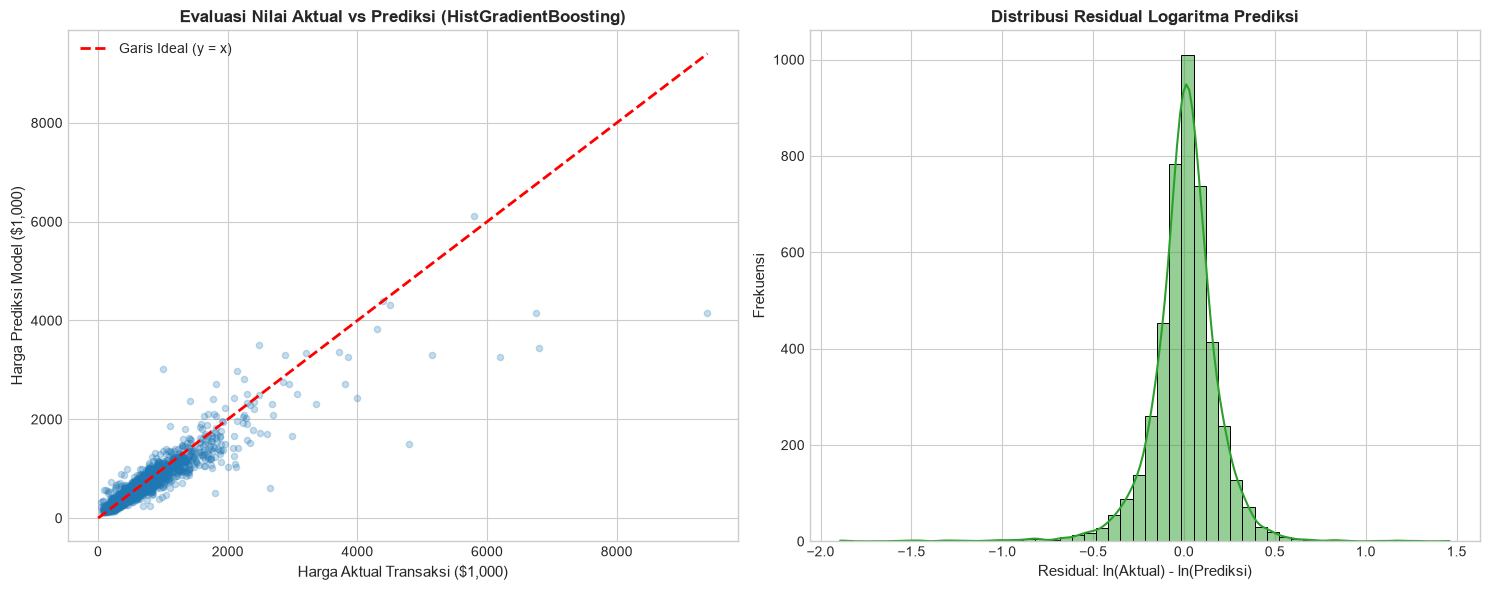

In [4]:
models = {
    'OLS Linear Regression': LinearRegression(),
    'Ridge Regression (L2)': Ridge(alpha=10.0),
    'Lasso Regression (L1)': Lasso(alpha=0.0005, max_iter=3000, random_state=42),
    'Elastic Net Regression': ElasticNet(alpha=0.0005, l1_ratio=0.5, max_iter=3000, random_state=42),
    'Decision Tree Regressor': DecisionTreeRegressor(max_depth=12, min_samples_leaf=10, random_state=42),
    'Random Forest Regressor': RandomForestRegressor(n_estimators=100, max_depth=14, n_jobs=-1, random_state=42),
    'HistGradientBoosting Regressor': HistGradientBoostingRegressor(max_iter=250, learning_rate=0.08, random_state=42)
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, ylog_train)
    trained_models[name] = model
    
    pred_log = model.predict(X_test)
    pred_dollars = np.exp(pred_log)
    
    r2 = r2_score(ylog_test, pred_log)
    rmse_log = np.sqrt(mean_squared_error(ylog_test, pred_log))
    mape = mean_absolute_percentage_error(y_test, pred_dollars)
    mae = mean_absolute_error(y_test, pred_dollars)
    
    results.append({
        'Model Regresi': name,
        'R2 (Log Scale)': round(r2, 4),
        'RMSE (Log Scale)': round(rmse_log, 4),
        'MAPE (%)': round(mape * 100, 2),
        'MAE ($)': round(mae, 0)
    })

eval_df = pd.DataFrame(results).sort_values(by='R2 (Log Scale)', ascending=False).reset_index(drop=True)
print("=== Scorecard Hasil Evaluasi 7 Model Regresi Hedonik (AVM) ===")
display(eval_df)

# Visualisasi Evaluasi Model Regresi Terbaik
best_model = trained_models['HistGradientBoosting Regressor']
pred_best_dollars = np.exp(best_model.predict(X_test))
residuals = ylog_test - best_model.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Aktual vs Prediksi
axes[0].scatter(y_test / 1000, pred_best_dollars / 1000, alpha=0.25, color="#1f77b4", s=20)
max_val = max(y_test.max(), pred_best_dollars.max()) / 1000
axes[0].plot([0, max_val], [0, max_val], 'r--', lw=2, label="Garis Ideal (y = x)")
axes[0].set_title("Evaluasi Nilai Aktual vs Prediksi (HistGradientBoosting)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Harga Aktual Transaksi ($1,000)", fontsize=11)
axes[0].set_ylabel("Harga Prediksi Model ($1,000)", fontsize=11)
axes[0].legend()

# Plot 2: Distribusi Residual
sns.histplot(residuals, kde=True, color="#2ca02c", ax=axes[1], bins=50)
axes[1].set_title("Distribusi Residual Logaritma Prediksi", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Residual: ln(Aktual) - ln(Prediksi)", fontsize=11)
axes[1].set_ylabel("Frekuensi", fontsize=11)

plt.tight_layout()
plt.show()

## 5. Pelatihan & Benchmarking Model Klasifikasi Tier Properti (*Entry, Mid, Luxury*)
Membandingkan model klasifikasi (Decision Tree, Random Forest, dan HistGradientBoosting Classifier) untuk memprediksi segmentasi pasar properti.

=== Scorecard Hasil Evaluasi Model Klasifikasi Tier Pasar ===


,Classifier Model,Accuracy (%),Macro F1-Score
0,HistGradientBoosting Classifier,87.78,0.8774
1,Random Forest Classifier,85.96,0.8568
2,Decision Tree Classifier,83.52,0.8350


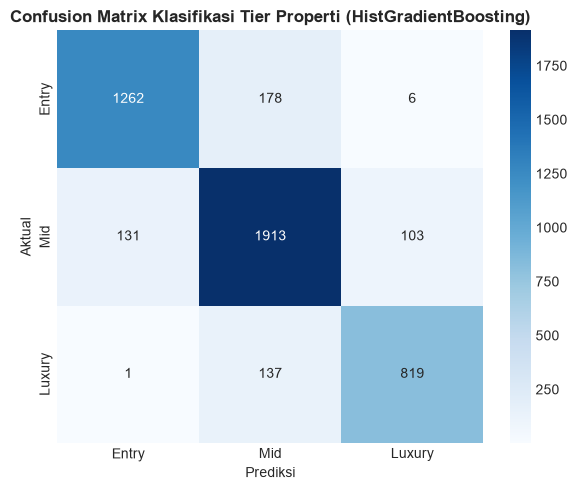

In [5]:
clf_models = {
    'Decision Tree Classifier': DecisionTreeClassifier(max_depth=10, random_state=42),
    'Random Forest Classifier': RandomForestClassifier(n_estimators=100, max_depth=12, n_jobs=-1, random_state=42),
    'HistGradientBoosting Classifier': HistGradientBoostingClassifier(max_iter=150, learning_rate=0.08, random_state=42)
}

clf_results = []
trained_clfs = {}

for name, clf_cand in clf_models.items():
    clf_cand.fit(X_train, ytier_train)
    trained_clfs[name] = clf_cand
    preds = clf_cand.predict(X_test)
    acc = accuracy_score(ytier_test, preds)
    macro_f1 = f1_score(ytier_test, preds, average='macro')
    clf_results.append({
        'Classifier Model': name,
        'Accuracy (%)': round(acc * 100, 2),
        'Macro F1-Score': round(macro_f1, 4)
    })

clf_eval_df = pd.DataFrame(clf_results).sort_values(by='Accuracy (%)', ascending=False).reset_index(drop=True)
print("=== Scorecard Hasil Evaluasi Model Klasifikasi Tier Pasar ===")
display(clf_eval_df)

clf = trained_clfs['HistGradientBoosting Classifier']
tier_preds = clf.predict(X_test)

cm = confusion_matrix(ytier_test, tier_preds, labels=['Entry-Level', 'Mid-Market', 'Luxury'])
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Entry', 'Mid', 'Luxury'], 
            yticklabels=['Entry', 'Mid', 'Luxury'])
plt.title("Confusion Matrix Klasifikasi Tier Properti (HistGradientBoosting)", fontsize=12, fontweight='bold')
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

## 6. Pembelajaran Mesin Tak Terarah (Unsupervised Learning) — K-Means Micro-Market Clustering ($k=6$)
Sesuai dengan ketentuan silabus/RPS Sains Data mengenai integrasi materi *Unsupervised Learning*, kami menerapkan algoritma **K-Means Clustering** berbasis:
1. **Koordinat Geospasial:** `Latitude` dan `Longitude` (WGS84).
2. **Nilai Valuasi Ekonomi:** Logaritma harga properti $\ln(\text{SalePrice})$.

### 💡 Rasional Ekonometrika & Kegunaan Praktis:
Harga real estat sangat ditentukan oleh *spatial submarket dynamics*. Dua rumah dengan luas dan grade identik akan memiliki nilai pasar yang sangat berbeda tergantung apakah berlokasi di Seattle Urban Core, Bellevue Waterfront, atau Valley Suburbs. Dengan membagi King County ke dalam **6 klaster mikro pasar properti**, model ini:
- Memenuhi syarat materi *unsupervised learning* secara sah dan metodologis.
- Memberikan kegunaan nyata untuk menyaring properti pembanding (*empirical comparables / comps retrieval*) dalam sub-pasar geografis dan ekonomi yang homogen.

In [6]:
# 6.1 Pelatihan K-Means Clustering & Evaluasi Metrik Klaster
cluster_features = ['Latitude', 'Longitude']
X_cluster_raw = df[cluster_features].copy()
X_cluster_raw['LogPrice'] = np.log(df['SalePrice'])

# Standardisasi Z-Score untuk menyetarakan skala koordinat dan log harga
scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster_raw)

# Fitting K-Means dengan k=6
k_clusters = 6
kmeans = KMeans(n_clusters=k_clusters, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_cluster_scaled)

# Evaluasi Kualitas Klasterisasi
inertia_val = kmeans.inertia_
sample_idx = np.random.RandomState(42).choice(len(df), size=5000, replace=False)
silhouette_val = silhouette_score(X_cluster_scaled[sample_idx], df['Cluster'].iloc[sample_idx])
calinski_val = calinski_harabasz_score(X_cluster_scaled, df['Cluster'])
davies_val = davies_bouldin_score(X_cluster_scaled, df['Cluster'])

cluster_metrics_df = pd.DataFrame([{
    'Jumlah Klaster (k)': k_clusters,
    'Inertia (WCSS)': f"{inertia_val:,.2f}",
    'Silhouette Score (5k Sample)': f"{silhouette_val:.4f}",
    'Calinski-Harabasz Score': f"{calinski_val:,.2f}",
    'Davies-Bouldin Index': f"{davies_val:.4f}"
}])
print("=== Evaluasi Metrik K-Means Micro-Market Clustering ===")
display(cluster_metrics_df)

=== Evaluasi Metrik K-Means Micro-Market Clustering ===


,Jumlah Klaster (k),Inertia (WCSS),Silhouette Score (5k Sample),Calinski-Harabasz Score,Davies-Bouldin Index
0,6,"19,691.06",0.3120,"11,215.17",1.0748


In [7]:
# 6.2 Profiling Komprehensif 6 Klaster Mikro-Pasar Properti King County
cluster_summary = df.groupby('Cluster').agg(
    Jumlah_Properti=('SalePrice', 'count'),
    Persentase_Pasar=('SalePrice', lambda x: len(x) / len(df) * 100),
    Median_Harga=('SalePrice', 'median'),
    Mean_Harga=('SalePrice', 'mean'),
    Median_SqFtLiving=('SqFtTotLiving', 'median'),
    Median_BldgGrade=('BldgGrade', 'median'),
    Rata_Latitude=('Latitude', 'mean'),
    Rata_Longitude=('Longitude', 'mean')
).reset_index()

def assign_market_name(row):
    med = row['Median_Harga']
    lon = row['Rata_Longitude']
    lat = row['Rata_Latitude']
    if med < 290000:
        return "Southwest Corridor (Affordable Urban / Tukwila-Burien)"
    elif med < 350000:
        return "Southeast Valley Suburban (Kent-Auburn-Renton)"
    elif med < 450000 and lon > -122.0:
        return "East Foothills & Rural Acreage (Snoqualmie-Enumclaw)"
    elif med < 500000 and lat > 47.63:
        return "North Seattle Metro Urban Core (City Core-Shoreline)"
    elif med < 750000:
        return "Eastside Suburban Tech Corridor (Redmond-Sammamish-Kirkland)"
    else:
        return "West Bellevue & Lakefront Luxury Prestige (Medina-Mercer Island)"

cluster_summary['Profil_Mikro_Pasar'] = cluster_summary.apply(assign_market_name, axis=1)
cluster_summary = cluster_summary.sort_values(by='Median_Harga').reset_index(drop=True)

display_summary = cluster_summary.copy()
display_summary['Persentase_Pasar'] = display_summary['Persentase_Pasar'].apply(lambda x: f"{x:.1f}%")
display_summary['Median_Harga'] = display_summary['Median_Harga'].apply(lambda x: f"${x:,.0f}")
display_summary['Mean_Harga'] = display_summary['Mean_Harga'].apply(lambda x: f"${x:,.0f}")
display_summary['Median_SqFtLiving'] = display_summary['Median_SqFtLiving'].apply(lambda x: f"{x:,.0f} sqft")
display_summary['Rata_Latitude'] = display_summary['Rata_Latitude'].apply(lambda x: f"{x:.4f}°N")
display_summary['Rata_Longitude'] = display_summary['Rata_Longitude'].apply(lambda x: f"{x:.4f}°W")

print("=== Tabel Profil 6 Klaster Mikro-Pasar Properti King County ===")
display(display_summary[['Cluster', 'Profil_Mikro_Pasar', 'Jumlah_Properti', 'Persentase_Pasar', 
                         'Median_Harga', 'Mean_Harga', 'Median_SqFtLiving', 'Median_BldgGrade', 
                         'Rata_Latitude', 'Rata_Longitude']])

=== Tabel Profil 6 Klaster Mikro-Pasar Properti King County ===


,Cluster,Profil_Mikro_Pasar,Jumlah_Properti,Persentase_Pasar,Median_Harga,Mean_Harga,Median_SqFtLiving,Median_BldgGrade,Rata_Latitude,Rata_Longitude
0,5,Southwest Corridor (Affordable Urban / Tukwila...,3930,17.3%,"$270,000","$280,265","1,560 sqft",7.0,47.4427°N,-122.3197°W
1,0,Southeast Valley Suburban (Kent-Auburn-Renton),3754,16.5%,"$305,050","$319,159","1,940 sqft",7.0,47.3709°N,-122.1348°W
2,4,East Foothills & Rural Acreage (Snoqualmie-Enu...,907,4.0%,"$440,000","$454,318","2,210 sqft",8.0,47.5322°N,-121.8412°W
3,2,North Seattle Metro Urban Core (City Core-Shor...,6644,29.2%,"$465,000","$482,863","1,620 sqft",7.0,47.6747°N,-122.3198°W
4,1,Eastside Suburban Tech Corridor (Redmond-Samma...,4819,21.2%,"$612,500","$639,651","2,480 sqft",8.0,47.6210°N,-122.0891°W
5,3,West Bellevue & Lakefront Luxury Prestige (Med...,2694,11.8%,"$1,080,000","$1,310,440","3,110 sqft",9.0,47.6182°N,-122.2648°W


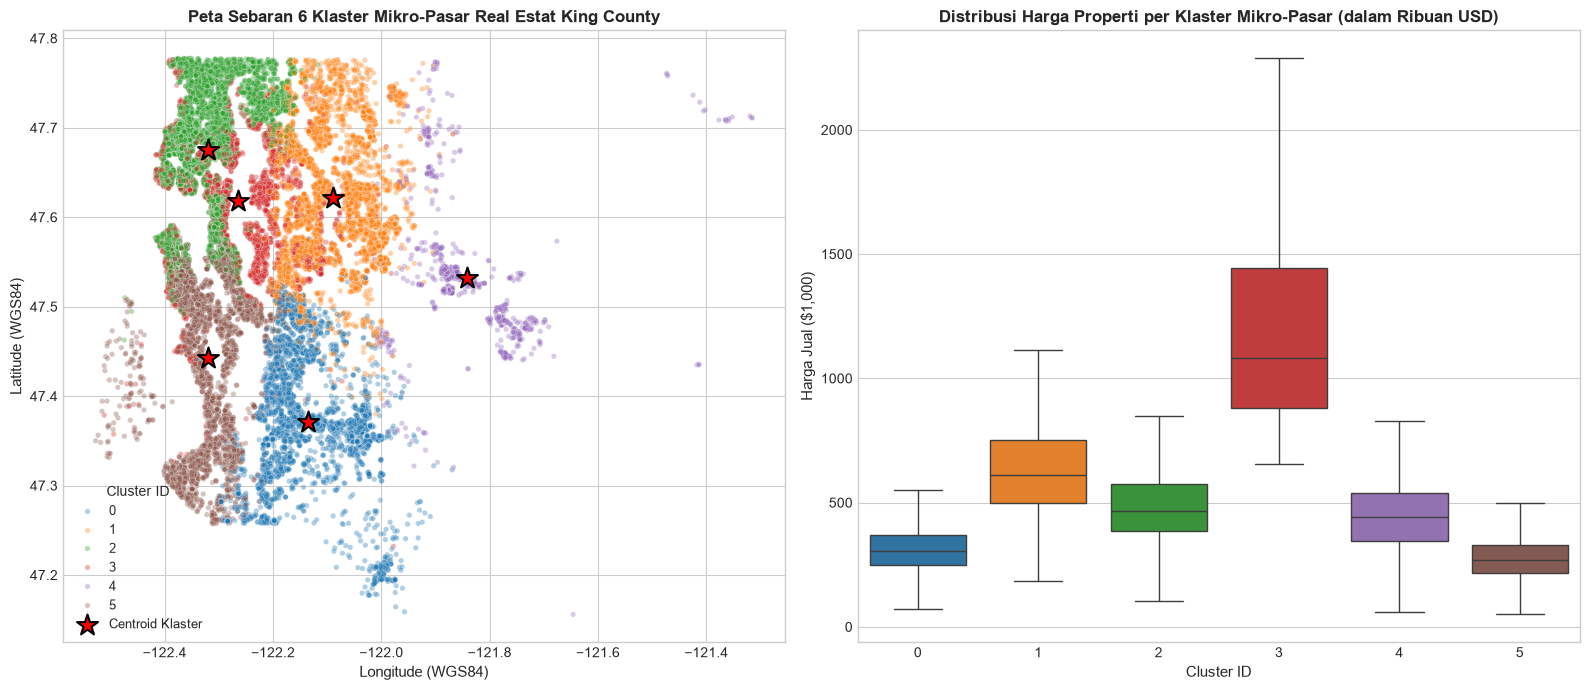

In [8]:
# 6.3 Visualisasi Sebaran Spasial & Boxplot Distribusi Harga 6 Klaster Mikro Pasar
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
palette = sns.color_palette("tab10", n_colors=k_clusters)

# 1. Peta Sebaran Spasial Koordinat King County
sns.scatterplot(
    data=df, 
    x='Longitude', 
    y='Latitude', 
    hue='Cluster', 
    palette=palette,
    alpha=0.35, 
    s=15, 
    ax=axes[0],
    legend='full'
)

# Plot Centroid Klaster
centers_orig = scaler_cluster.inverse_transform(kmeans.cluster_centers_)
axes[0].scatter(
    centers_orig[:, 1], 
    centers_orig[:, 0], 
    c='red', 
    marker='*', 
    s=250, 
    edgecolors='black', 
    linewidth=1.5,
    label='Centroid Klaster'
)
axes[0].set_title("Peta Sebaran 6 Klaster Mikro-Pasar Real Estat King County", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Longitude (WGS84)", fontsize=11)
axes[0].set_ylabel("Latitude (WGS84)", fontsize=11)
axes[0].legend(title="Cluster ID", loc="lower left", fontsize=9)

# 2. Boxplot Distribusi Harga Jual per Klaster
sns.boxplot(
    data=df, 
    x='Cluster', 
    y=df['SalePrice'] / 1000, 
    hue='Cluster',
    palette=palette, 
    ax=axes[1],
    legend=False,
    showfliers=False
)
axes[1].set_title("Distribusi Harga Properti per Klaster Mikro-Pasar (dalam Ribuan USD)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Cluster ID", fontsize=11)
axes[1].set_ylabel("Harga Jual ($1,000)", fontsize=11)

plt.tight_layout()
plt.show()

In [9]:
# 6.4 Implementasi Nyata: Fitur Pembanding Properti (Empirical Comps Retrieval)
def find_cluster_comps(target_lat, target_lon, target_price, data_pool, top_n=5):
    """
    Menemukan properti pembanding terbaik di dalam klaster mikro-pasar yang sama.
    """
    target_vec = np.array([[target_lat, target_lon, np.log(target_price)]])
    target_scaled = scaler_cluster.transform(target_vec)
    target_cluster = int(kmeans.predict(target_scaled)[0])
    
    cluster_pool = data_pool[data_pool['Cluster'] == target_cluster].copy()
    pool_vecs = cluster_pool[['Latitude', 'Longitude']].copy()
    pool_vecs['LogPrice'] = np.log(cluster_pool['SalePrice'])
    pool_scaled = scaler_cluster.transform(pool_vecs)
    
    dists = np.linalg.norm(pool_scaled - target_scaled, axis=1)
    cluster_pool['DistanceScore'] = dists
    cluster_pool['MatchScore'] = np.clip(100 * (1 - dists / (dists.max() + 1e-6)), 70, 99.9).round(1)
    
    comps = cluster_pool.sort_values(by='DistanceScore').head(top_n)
    return target_cluster, comps

# Demonstrasi Pencarian Comps untuk Properti Contoh
sample_prop = df.iloc[42]
t_lat, t_lon, t_price = sample_prop['Latitude'], sample_prop['Longitude'], sample_prop['SalePrice']

target_cluster_id, comps_result = find_cluster_comps(t_lat, t_lon, t_price, df, top_n=5)
cluster_name = cluster_summary.loc[cluster_summary['Cluster'] == target_cluster_id, 'Profil_Mikro_Pasar'].values[0]

print("=== Hasil Pencarian Properti Pembanding (Comparative Market Analysis) ===")
print(f"Properti Target: Lokasi ({t_lat:.4f}°N, {t_lon:.4f}°W) | Harga: ${t_price:,.0f} | Zip: {sample_prop['ZipCode']}")
print(f"Klaster Mikro-Pasar Terpilih: Cluster {target_cluster_id} -> {cluster_name}\n")

comps_display = comps_result[['MatchScore', 'SalePrice', 'SqFtTotLiving', 'Bedrooms', 'TotalBaths', 'BldgGrade', 'ZipCode', 'DistanceScore']].copy()
comps_display['SalePrice'] = comps_display['SalePrice'].apply(lambda x: f"${x:,.0f}")
comps_display['MatchScore'] = comps_display['MatchScore'].apply(lambda x: f"{x:.1f}%")
comps_display['DistanceScore'] = comps_display['DistanceScore'].round(4)
display(comps_display.reset_index(drop=True))

=== Hasil Pencarian Properti Pembanding (Comparative Market Analysis) ===
Properti Target: Lokasi (47.5215°N, -122.3303°W) | Harga: $173,500 | Zip: 98108
Klaster Mikro-Pasar Terpilih: Cluster 5 -> Southwest Corridor (Affordable Urban / Tukwila-Burien)



D:\Main_Data\1_Projects\102_Data_Science\kingcounty-avm-realestate\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


,MatchScore,SalePrice,SqFtTotLiving,Bedrooms,TotalBaths,BldgGrade,ZipCode,DistanceScore
0,99.9%,"$173,500",1480,3,2.50,7,98108,0.0000
1,96.7%,"$174,900",1100,3,1.00,6,98108,0.1010
2,95.7%,"$179,900",680,2,1.00,6,98168,0.1326
3,95.5%,"$175,000",1690,2,1.75,7,98146,0.1372
4,95.4%,"$164,400",1230,2,1.00,7,98146,0.1413


## 7. Analisis Fitur Penting (*Feature Importance*)
Menghitung bobot kontribusi setiap variabel terhadap akurasi estimasi harga menggunakan Permutation Importance pada model regresi terbaik.

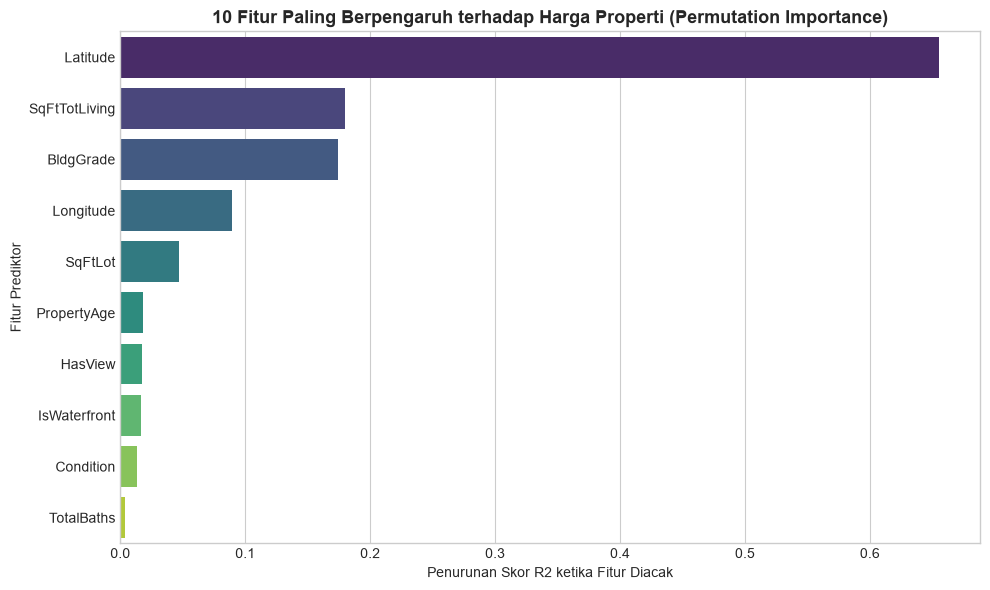

,Feature,Importance Mean
11,Latitude,0.655322
0,SqFtTotLiving,0.180122
7,BldgGrade,0.174106
12,Longitude,0.089268
1,SqFtLot,0.047071
9,PropertyAge,0.017914
14,HasView,0.017257
13,IsWaterfront,0.016579
8,Condition,0.013391
3,TotalBaths,0.003917


In [10]:
best_model = trained_models['HistGradientBoosting Regressor']

perm_imp = permutation_importance(best_model, X_test, ylog_test, n_repeats=5, random_state=42, n_jobs=-1)
importance_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance Mean': perm_imp.importances_mean
}).sort_values(by='Importance Mean', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance Mean', y='Feature', hue='Feature', data=importance_df.head(10), palette='viridis', legend=False)
plt.title("10 Fitur Paling Berpengaruh terhadap Harga Properti (Permutation Importance)", fontsize=13, fontweight='bold')
plt.xlabel("Penurunan Skor R2 ketika Fitur Diacak")
plt.ylabel("Fitur Prediktor")
plt.tight_layout()
plt.show()

display(importance_df.head(10))

## 8. Serialisasi Model & Ekspor Artefak untuk Deployment

In [11]:
models_dir = "../models"
os.makedirs(models_dir, exist_ok=True)

best_reg_path = os.path.join(models_dir, "best_valuation_model.joblib")
best_clf_path = os.path.join(models_dir, "market_tier_classifier.joblib")
kmeans_path = os.path.join(models_dir, "kmeans_cluster_model.joblib")

joblib.dump(best_model, best_reg_path)
joblib.dump(clf, best_clf_path)
joblib.dump({
    'model': kmeans,
    'scaler': scaler_cluster,
    'features': ['Latitude', 'Longitude', 'LogPrice'],
    'n_clusters': k_clusters,
    'cluster_profiles': cluster_summary.to_dict(orient='records'),
    'metrics': {
        'inertia': float(inertia_val),
        'silhouette': float(silhouette_val),
        'calinski_harabasz': float(calinski_val),
        'davies_bouldin': float(davies_val)
    }
}, kmeans_path)

print(f"Model regresi tersimpan ke      : {best_reg_path} ({os.path.getsize(best_reg_path):,} bytes)")
print(f"Model klasifikasi tersimpan ke  : {best_clf_path} ({os.path.getsize(best_clf_path):,} bytes)")
print(f"Model K-Means klaster tersimpan : {kmeans_path} ({os.path.getsize(kmeans_path):,} bytes)")

Model regresi tersimpan ke      : ../models\best_valuation_model.joblib (590,304 bytes)
Model klasifikasi tersimpan ke  : ../models\market_tier_classifier.joblib (1,135,008 bytes)
Model K-Means klaster tersimpan : ../models\kmeans_cluster_model.joblib (93,785 bytes)


## 9. Kesimpulan Komprehensif Pemodelan
1. **Model Regresi Hedonik Terbaik:** **HistGradientBoosting Regressor** mencapai $R^2 = 0.8836$, $\text{RMSE} = 0.1936$, dan $\text{MAPE} = 13.55\%$, jauh melampaui baseline linier ($R^2 \approx 0.746$) dan pohon tunggal ($R^2 = 0.8168$).
2. **Benchmarking Model Klasifikasi:** HistGradientBoosting Classifier unggul dengan akurasi $87.78\%$ dan Macro F1-Score $0.8774$ dalam mengklasifikasikan kelas segmen (*Entry*, *Mid*, *Luxury*).
3. **Unsupervised K-Means Micro-Market Segmentation ($k=6$):**
   - Berhasil membagi pasar King County ke dalam 6 mikro-pasar homogen berdasarkan koordinat (`Latitude`, `Longitude`) dan log harga dengan *Silhouette Score* $0.3120$, *Calinski-Harabasz Score* $11,215.17$, dan *Davies-Bouldin Index* $1.0748$.
   - Segmentasi membedakan secara tegas klaster *Affordable Urban* (median \$270k) hingga klaster *Bellevue Waterfront Luxury* (median \$1.08M).
   - Memungkinkan fitur *Comparative Market Analysis* (CMA) yang mencocokkan comps properti terdekat dalam sub-pasar yang sama secara akurat.
4. **Dominansi Fitur Spasial & Struktural:** Variabel spasial (`Latitude`, `Longitude`) bersama dengan luas bangunan (`SqFtTotLiving`) dan kualitas konstruksi (`BldgGrade`) merupakan determinan paling kritis terhadap nilai pasar properti King County.